In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.tree import plot_tree
from google.colab import drive
drive.mount('/content/drive')
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
import tensorflow.keras.backend as K
from tensorflow.keras.losses import binary_crossentropy
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

Mounted at /content/drive


In [ ]:
train_files = [
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Wednesday-workingHours.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Tuesday-WorkingHours.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
]

In [ ]:
test_files = [
    "/content/drive/MyDrive/Colab Notebooks/SSH-Bruteforce.csv",
    #"/content/drive/MyDrive/Colab Notebooks/DDoS attacks-LOIC-HTTP.csv",
    "/content/drive/MyDrive/Colab Notebooks/DoS attacks-Hulk.csv",
    "/content/drive/MyDrive/Colab Notebooks/FTP-BruteForce.csv",
    "/content/drive/MyDrive/Colab Notebooks/Infilteration.csv",
    #"/content/drive/MyDrive/Colab Notebooks/DDOS attack-HOIC.csv",
    "/content/drive/MyDrive/Colab Notebooks/Bot.csv",
    "/content/drive/MyDrive/Colab Notebooks/DoS attacks-SlowHTTPTest.csv",
    "/content/drive/MyDrive/Colab Notebooks/DoS attacks-GoldenEye.csv",
    "/content/drive/MyDrive/Colab Notebooks/Brute Force -Web.csv",
    "/content/drive/MyDrive/Colab Notebooks/Brute Force -XSS.csv",
    "/content/drive/MyDrive/Colab Notebooks/DDOS attack-LOIC-UDP.csv",
    "/content/drive/MyDrive/Colab Notebooks/DoS attacks-Slowloris.csv",
    "/content/drive/MyDrive/Colab Notebooks/SQL Injection.csv"
]

In [ ]:
# definované features
selected_features = [
    'Average Packet Size', 'Max Packet Length', 'Avg Bwd Segment Size',
    'Bwd Packet Length Max', 'Packet Length Mean',
    'Bwd Packet Length Std', 'Packet Length Variance',
    'Avg Fwd Segment Size', 'Bwd Packet Length Mean', 'Packet Length Std',
    'Subflow Fwd Bytes', 'Fwd Packet Length Max',
    'Fwd Packet Length Min', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets'
]

In [ ]:
# funkcia na načítanie a spracovanie dát
def load_and_process(files):
    dfs = []
    for file in files:
        df = pd.read_csv(file)
        df.columns = df.columns.str.strip()

        if df['Label'].dtype == object:
            df['Label'] = df['Label'].apply(lambda x: 0 if isinstance(x, str) and "BENIGN" in x.upper() else 1)
        else:
            df['Label'] = df['Label'].apply(lambda x: 0 if x == 0 else 1)

        dfs.append(df)
    df_all = pd.concat(dfs, ignore_index=True)
    X = df_all[selected_features].replace([np.inf, -np.inf], np.nan).dropna()
    y = df_all['Label'].loc[X.index]
    return X, y

In [ ]:
# funkcia na načítanie a spracovanie dát CIC-IDS2018
def load_and_processCIC2018(files):
    rename_map = {
        'Pkt Size Avg': 'Average Packet Size',
        'Pkt Len Max': 'Max Packet Length',
        'Bwd Seg Size Avg': 'Avg Bwd Segment Size',
        'Bwd Pkt Len Max': 'Bwd Packet Length Max',
        'Pkt Len Mean': 'Packet Length Mean',
        'Bwd Pkt Len Std': 'Bwd Packet Length Std',
        'Pkt Len Var': 'Packet Length Variance',
        'Fwd Seg Size Avg': 'Avg Fwd Segment Size',
        'Bwd Pkt Len Mean': 'Bwd Packet Length Mean',
        'Pkt Len Std': 'Packet Length Std',
        'Subflow Fwd Byts': 'Subflow Fwd Bytes',
        'Fwd Pkt Len Max': 'Fwd Packet Length Max',
        'Fwd Pkt Len Min': 'Fwd Packet Length Min',
        'TotLen Fwd Pkts': 'Total Length of Fwd Packets',
        'TotLen Bwd Pkts': 'Total Length of Bwd Packets',
    }

    dfs = []
    for file in files:
        df = pd.read_csv(file)
        df.columns = df.columns.str.strip()

        # Přejmenování sloupců
        df = df.rename(columns=rename_map)

        # Label preprocessing
        if df['Label'].dtype == object:
            df['Label'] = df['Label'].apply(lambda x: 0 if isinstance(x, str) and "BENIGN" in x.upper() else 1)
        else:
            df['Label'] = df['Label'].apply(lambda x: 0 if x == 0 else 1)

        dfs.append(df)

    df_all = pd.concat(dfs, ignore_index=True)

    # Výběr správných feature podle CIC2017 názvů
    X = df_all[selected_features].replace([np.inf, -np.inf], np.nan).dropna()
    y = df_all['Label'].loc[X.index]

    return X, y

In [ ]:
# načítanie trénovacích a testovacích dát
X_train, y_train = load_and_process(train_files)
X_test, y_test = load_and_processCIC2018(test_files)

In [ ]:
# škálovanie
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
def focal_loss(gamma=2., alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        BCE = binary_crossentropy(y_true, y_pred)
        pt = K.exp(-BCE)
        return alpha * (1 - pt) ** gamma * BCE
    return focal_loss_fixed

In [ ]:
#  Definovanie a trénovanie NN modelu
model = models.Sequential([
    layers.Dense(256, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])


optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer, loss=focal_loss(gamma=2., alpha=0.25), metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    epochs=30, batch_size=512,
    validation_split=0.1,
    verbose=1,
    class_weight = {0: 1.0, 1: 2.0},
    callbacks=[early_stop]
)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.7770 - loss: 0.0337 - val_accuracy: 0.8968 - val_loss: 0.0100
Epoch 2/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8118 - loss: 0.0232 - val_accuracy: 0.8797 - val_loss: 0.0126
Epoch 3/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8487 - loss: 0.0208 - val_accuracy: 0.9100 - val_loss: 0.0124
Epoch 4/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8931 - loss: 0.0176 - val_accuracy: 0.9799 - val_loss: 0.0067
Epoch 5/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9166 - loss: 0.0154 - val_accuracy: 0.9813 - val_loss: 0.0062
Epoch 6/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9231 - loss: 0.0143 - val_accuracy: 0.9815 - val_loss: 0.0068
Epoch 7/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9260 - loss: 0.0136 - val_accuracy: 0.9834 - val_loss: 0.0062
Epoch 8/30
4045/4045 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9306 - loss: 0

In [ ]:
# 3. --- Model ---
rf_model = RandomForestClassifier(
    class_weight="balanced",
    max_depth=20,
    max_features='log2',
    min_samples_leaf=1,
    min_samples_split=5,
    n_estimators=100,
    oob_score=True,
    random_state=42
)

In [ ]:
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=20,
                       max_features='log2', min_samples_split=5, oob_score=True,
                       random_state=42)

In [ ]:
# Pôvodné pravdepodobnosti
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]
nn_probs = model.predict(X_test_scaled).flatten()

# Normalizácia podľa individuálnych optimal thresholdov
rf_probs_adj = rf_probs / 0.5
nn_probs_adj = nn_probs / 0.4

# Soft voting (rovnaké váhy ako prvý pokus)
ensemble_probs = 0.5 * rf_probs_adj + 0.5 * nn_probs_adj
ensemble_preds = (ensemble_probs >= 1.0).astype(int)


# Vyhodnotenie
from sklearn.metrics import classification_report, roc_auc_score
print(classification_report(y_test, ensemble_preds))
print(f"Ensemble ROC AUC: {roc_auc_score(y_test, ensemble_probs):.4f}")

158463/158463 ━━━━━━━━━━━━━━━━━━━━ 206s 1ms/step
              precision    recall  f1-score   support

           0       0.90      0.76      0.82   3584761
           1       0.58      0.79      0.66   1486032

    accuracy                           0.77   5070793
   macro avg       0.74      0.77      0.74   5070793
weighted avg       0.80      0.77      0.78   5070793

Ensemble ROC AUC: 0.8108


In [ ]:
# normalizácia podľa individuálnych optimálnych thresholdov
rf_probs_adj = rf_probs / 0.6
nn_probs_adj = nn_probs / 0.5

# soft voting
ensemble_probs = 0.4 * rf_probs_adj + 0.6 * nn_probs_adj
ensemble_preds = (ensemble_probs >= 0.5).astype(int)


# Vyhodnotenie
from sklearn.metrics import classification_report, roc_auc_score
print(classification_report(y_test, ensemble_preds))
print(f"Ensemble ROC AUC: {roc_auc_score(y_test, ensemble_probs):.4f}")

              precision    recall  f1-score   support

           0       0.94      0.74      0.83   3584761
           1       0.58      0.89      0.71   1486032

    accuracy                           0.78   5070793
   macro avg       0.76      0.81      0.77   5070793
weighted avg       0.84      0.78      0.79   5070793

Ensemble ROC AUC: 0.8087


In [ ]:
print("Rozdelenie tried v y_test:")
print(y_test.value_counts())

print("\nShape X_test_scaled:", X_test_scaled.shape)
print("Missing values:", np.isnan(X_test_scaled).sum())

Rozdelenie tried v y_test:
Label
0    6876913
1    2748235
Name: count, dtype: int64

Shape X_test_scaled: (9625148, 15)
Missing values: 0


In [ ]:
# napr.
print(X_train.columns.tolist())
print(X_test.columns.tolist())

['Average Packet Size', 'Max Packet Length', 'Avg Bwd Segment Size', 'Bwd Packet Length Max', 'Packet Length Mean', 'Bwd Packet Length Std', 'Packet Length Variance', 'Avg Fwd Segment Size', 'Bwd Packet Length Mean', 'Packet Length Std', 'Subflow Fwd Bytes', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets']
['Average Packet Size', 'Max Packet Length', 'Avg Bwd Segment Size', 'Bwd Packet Length Max', 'Packet Length Mean', 'Bwd Packet Length Std', 'Packet Length Variance', 'Avg Fwd Segment Size', 'Bwd Packet Length Mean', 'Packet Length Std', 'Subflow Fwd Bytes', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets']


In [ ]:
print("== RF na CIC2018 ==")
print(classification_report(y_test, rf_pred))

print("== NN na CIC2018 ==")
print(classification_report(y_test, nn_pred))

# Normalizácia podľa individuálnych optimal thresholdov
rf_probs_adj = rf_probs / 0.6
nn_probs_adj = nn_probs / 0.5

# Soft voting (rovnaké váhy ako prvý pokus)
ensemble_probs = 0.4 * rf_probs_adj + 0.6 * nn_probs_adj
ensemble_preds = (ensemble_probs >= 0.5).astype(int)

print(classification_report(y_test, ensemble_preds))
print(f"Ensemble ROC AUC: {roc_auc_score(y_test, ensemble_probs):.4f}")

== RF na CIC2018 ==


ValueError: Found input variables with inconsistent numbers of samples: [5070793, 9625148]

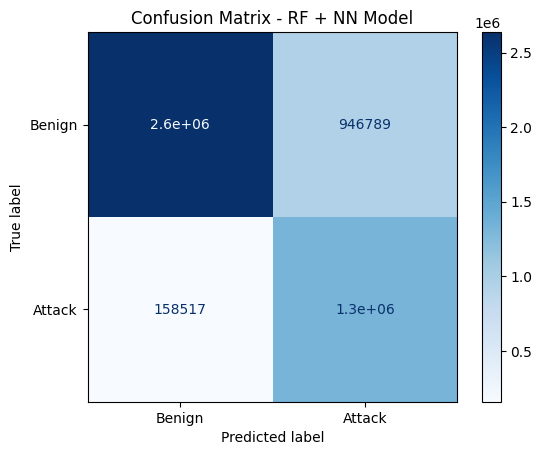

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, ensemble_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Attack'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - RF + NN Model')
plt.grid(False)
plt.show()